# Imports

In [17]:
import html
import json
import math
import random
import re
from collections import Counter
from pathlib import Path

import datasets
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report
from sklearn.metrics import RocCurveDisplay, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.set_float32_matmul_precision('high')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)
ARTIFACTS = Path('transformer_1_artifacts')
ARTIFACTS.mkdir(exist_ok=True)

cuda


# Tokenizer

Train your own tokenizer on an English corpus or load a pretrained tokenizer for English sentences (see the one used in class)

In [18]:
def clean_text(text):
    text = html.unescape(text)
    text = re.sub(r'<[^>]+>', ' ', text)
    return re.sub(r'\s+', ' ', text).strip()


class Tokenizer:
    def __init__(self, coverage=0.99):
        self.coverage = coverage
        self.vocab = {'[PAD]': 0, '[UNK]': 1, '[CLS]': 2}
        self.pad_token_id = 0
        self.unk_token_id = 1
        self.cls_token_id = 2

    def tokenize(self, text):
        return re.findall(r"[a-z]+(?:'[a-z]+)*|[0-9]+|[^\w\s]", clean_text(text).lower())

    def fit(self, texts):
        counts = Counter(token for text in texts for token in self.tokenize(text))
        total = sum(counts.values())
        covered = 0
        for token, count in counts.most_common():
            self.vocab[token] = len(self.vocab)
            covered += count
            if covered >= self.coverage * total:
                break
        self.actual_coverage = covered / total

    def encode(self, text, max_length):
        tokens = self.tokenize(text)[:max_length - 1]
        return [self.cls_token_id] + [self.vocab.get(token, self.unk_token_id) for token in tokens]

    def __len__(self):
        return len(self.vocab)


raw_train = datasets.load_dataset('stanfordnlp/imdb', split='train')
raw_test = datasets.load_dataset('stanfordnlp/imdb', split='test')
train_frame = raw_train.to_pandas()
test_frame = raw_test.to_pandas()
for frame in [train_frame, test_frame]:
    frame['text'] = frame.text.map(clean_text)
    frame['key'] = frame.text.str.casefold()

before = len(train_frame)
conflicting = train_frame.groupby('key').label.nunique()
train_frame = train_frame[~train_frame.key.isin(conflicting[conflicting > 1].index)]
train_frame = train_frame.drop_duplicates('key')
train_frame = train_frame[~train_frame.key.isin(test_frame.key)]
print('Удалено из train повторов, пересечений с test и спорных меток:', before - len(train_frame))
train_frame, val_frame = train_test_split(
    train_frame, test_size=0.1, stratify=train_frame.label, random_state=SEED
)
tokenizer = Tokenizer(coverage=0.98)
tokenizer.fit(train_frame.text)
PAD = tokenizer.pad_token_id
print('Размер словаря:', len(tokenizer))
print(f'Покрытие токенов train: {100 * tokenizer.actual_coverage:.4f}%')
val_counts = Counter(token for text in val_frame.text for token in tokenizer.tokenize(text))
val_unknown = sum(count for token, count in val_counts.items() if token not in tokenizer.vocab)
print(f'[UNK] на validation: {100 * val_unknown / sum(val_counts.values()):.4f}%')
print(tokenizer.tokenize("I didn't like the movie, but the music was great!"))
(ARTIFACTS / 'vocab.json').write_text(json.dumps(tokenizer.vocab, ensure_ascii=False, indent=2));

Удалено из train повторов, пересечений с test и спорных меток: 221
Размер словаря: 21706
Покрытие токенов train: 98.0001%
[UNK] на validation: 2.2776%
['i', "didn't", 'like', 'the', 'movie', ',', 'but', 'the', 'music', 'was', 'great', '!']


# Dataset

Load the dataset (we will be using [imdb](https://huggingface.co/datasets/stanfordnlp/imdb)). Pretokenize data or make a loader that tokenizes the sentenses as you iterate through the dataset.

In [19]:
frames = {'train': train_frame, 'validation': val_frame, 'test': test_frame}
display(pd.DataFrame({name: frame.label.value_counts() for name, frame in frames.items()})
        .rename(index={0: 'negative', 1: 'positive'}))
display(train_frame[['text', 'label']].sample(4, random_state=SEED).reset_index(drop=True))

,train,validation,test
label,,,
negative,11102,1234,12500
positive,11199,1244,12500


,text,label
0,I'm starting to write this review during a bre...,0
1,"He's stocky, sweaty, slightly cross-eyed and r...",1
2,Richard Willaims is an animation god. He was h...,1
3,"Just after I saw the movie, the true magic fee...",1


In [20]:
MAX_LENGTH = 1024
BATCH_SIZE = 64

encoded = {}
length_rows = []
for name, frame in frames.items():
    lengths = np.array([len(tokenizer.tokenize(text)) + 1 for text in frame.text])
    encoded[name] = [
        {'ids': tokenizer.encode(text, MAX_LENGTH), 'label': int(label)}
        for text, label in zip(frame.text, frame.label)
    ]
    removed = np.maximum(lengths - MAX_LENGTH, 0)
    length_rows.append({'Выборка': name, 'Отзывов': len(frame),
                        'Медиана токенов': np.median(lengths),
                        'Обрезано, %': 100 * np.mean(removed > 0),
                        'Отрезано токенов в среднем (все отзывы)': removed.mean(),
                        'Отрезано токенов в среднем (обрезанные)': removed.sum() / max(1, np.count_nonzero(removed))})
display(pd.DataFrame(length_rows).set_index('Выборка'))
print('В модель поступают первые', MAX_LENGTH - 1, 'токенов отзыва и [CLS].')


def collate_batch(rows):
    ids = [torch.tensor(row['ids']) for row in rows]
    ids = pad_sequence(ids, batch_first=True, padding_value=PAD)
    labels = torch.tensor([row['label'] for row in rows], dtype=torch.float32)
    return ids, labels


generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(encoded['train'], batch_size=BATCH_SIZE, shuffle=True,
                          generator=generator, collate_fn=collate_batch)
val_loader = DataLoader(encoded['validation'], batch_size=BATCH_SIZE, collate_fn=collate_batch)
test_loader = DataLoader(encoded['test'], batch_size=BATCH_SIZE, collate_fn=collate_batch)
ids, labels = next(iter(val_loader))
print('Токены:', ids.shape, 'Метки:', labels.shape)

,Отзывов,Медиана токенов,"Обрезано, %",Отрезано токенов в среднем (все отзывы),Отрезано токенов в среднем (обрезанные)
Выборка,,,,,
train,22301,203.0,1.134478,1.516569,133.679842
validation,2478,202.0,1.170299,1.534705,131.137931
test,25000,201.0,1.096000,1.192880,108.839416


В модель поступают первые 1023 токенов отзыва и [CLS].
Токены: torch.Size([64, 616]) Метки: torch.Size([64])


# Model

Implement your model. The model should have the Transformer architecture. Remember to mask out padding tokens.

In [21]:
class MultiHeadAttention(nn.Module):
    def __init__(self, embedding_size, num_heads, dropout=0.2):
        super().__init__()
        self.num_heads = num_heads
        self.head_size = embedding_size // num_heads
        self.qkv = nn.Linear(embedding_size, 3 * embedding_size)
        self.output = nn.Linear(embedding_size, embedding_size)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, mask):
        batch, length, size = x.shape
        qkv = self.qkv(x).reshape(batch, length, 3, self.num_heads, self.head_size)
        q, k, v = qkv.permute(2, 0, 3, 1, 4).unbind(0)
        scores = q @ k.transpose(-2, -1) / math.sqrt(self.head_size)
        scores = scores.masked_fill(~mask[:, None, None, :], float('-inf'))
        weights = scores.float().softmax(dim=-1).to(q.dtype)
        context = self.dropout(weights) @ v
        context = context.transpose(1, 2).reshape(batch, length, size)
        return self.output(context), weights

In [22]:
class TransformerBlock(nn.Module):
    def __init__(self, embedding_size, num_heads, dropout=0.2):
        super().__init__()
        self.norm1 = nn.LayerNorm(embedding_size)
        self.norm2 = nn.LayerNorm(embedding_size)
        self.attention = MultiHeadAttention(embedding_size, num_heads, dropout)
        self.feed_forward = nn.Sequential(
            nn.Linear(embedding_size, 4 * embedding_size),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(4 * embedding_size, embedding_size),
        )
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, mask):
        context, weights = self.attention(self.norm1(x), mask)
        x = x + self.dropout(context)
        x = x + self.dropout(self.feed_forward(self.norm2(x)))
        return x * mask.unsqueeze(-1), weights


class TransformerClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_size, max_length, num_blocks, num_heads, pad_token_id):
        super().__init__()
        self.pad_token_id = pad_token_id
        self.max_length = max_length
        self.embedding = nn.Embedding(vocab_size, embedding_size, padding_idx=pad_token_id)
        positions = torch.arange(max_length).unsqueeze(1)
        frequencies = torch.exp(torch.arange(0, embedding_size, 2) * (-math.log(10000.0) / embedding_size))
        position_encoding = torch.zeros(max_length, embedding_size)
        position_encoding[:, 0::2] = torch.sin(positions * frequencies)
        position_encoding[:, 1::2] = torch.cos(positions * frequencies)
        self.register_buffer('position_encoding', position_encoding)
        self.dropout = nn.Dropout(0.2)
        self.blocks = nn.ModuleList([
            TransformerBlock(embedding_size, num_heads) for _ in range(num_blocks)
        ])
        self.norm = nn.LayerNorm(embedding_size)
        self.classifier = nn.Linear(embedding_size, 1)

    def forward(self, ids, return_attention=False):
        mask = ids.ne(self.pad_token_id)
        x = self.embedding(ids) + self.position_encoding[:ids.size(1)]
        x = self.dropout(x) * mask.unsqueeze(-1)
        attention = []
        for block in self.blocks:
            x, weights = block(x, mask)
            if return_attention:
                attention.append(weights)
        logits = self.classifier(self.norm(x[:, 0])).squeeze(-1)
        if return_attention:
            return logits, attention
        return logits


def get_model(vocab_size, embedding_size, max_length, num_blocks, num_heads, pad_token_id):
    return TransformerClassifier(vocab_size, embedding_size, max_length,
                                 num_blocks, num_heads, pad_token_id)

# Training

Train the model. Choose model size, batch size, loss, learning rate schedule.

In [23]:
model_config = dict(
    vocab_size=len(tokenizer),
    embedding_size=16,
    max_length=MAX_LENGTH,
    num_blocks=2,
    num_heads=4,
    pad_token_id=PAD,
)
model = get_model(**model_config).to(device)
print('Параметров:', sum(p.numel() for p in model.parameters()))

Параметров: 353905


In [24]:
EPOCHS = 40
PATIENCE = 4
LEARNING_RATE = 3e-4

criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.01)
total_steps = EPOCHS * len(train_loader)
warmup_steps = max(1, total_steps // 10)


def lr_multiplier(step):
    if step < warmup_steps:
        return (step + 1) / warmup_steps
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return 0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * min(progress, 1)))


scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_multiplier)


def run_epoch(loader, training=False):
    model.train(training)
    total_loss = 0.0
    all_labels, all_probs = [], []
    with torch.set_grad_enabled(training):
        for ids, labels in tqdm(loader, leave=False):
            ids, labels = ids.to(device), labels.to(device)
            if training:
                optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, dtype=torch.bfloat16,
                                enabled=device.type == 'cuda'):
                logits = model(ids)
                loss = criterion(logits, labels)
            if training:
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
                scheduler.step()
            total_loss += loss.item() * len(labels)
            all_labels.extend(labels.cpu().tolist())
            all_probs.extend(logits.detach().float().sigmoid().cpu().tolist())
    labels = np.array(all_labels, dtype=int)
    probs = np.array(all_probs)
    metrics = {
        'loss': total_loss / len(labels),
        'accuracy': accuracy_score(labels, probs >= 0.5),
        'roc_auc': roc_auc_score(labels, probs),
    }
    return metrics, labels, probs

Эпоха 1: train loss=0.7316, val loss=0.6940, val AUC=0.4657


Эпоха 2: train loss=0.7006, val loss=0.6940, val AUC=0.5080


Эпоха 3: train loss=0.6961, val loss=0.6930, val AUC=0.5808


Эпоха 4: train loss=0.6917, val loss=0.6854, val AUC=0.6530


Эпоха 5: train loss=0.6600, val loss=0.5906, val AUC=0.7593


...

Эпоха 33: train loss=0.2944, val loss=0.3446, val AUC=0.9399


Эпоха 34: train loss=0.3001, val loss=0.3494, val AUC=0.9401


Эпоха 35: train loss=0.2928, val loss=0.3529, val AUC=0.9402


Эпоха 36: train loss=0.2940, val loss=0.3507, val AUC=0.9404


Эпоха 37: train loss=0.2927, val loss=0.3458, val AUC=0.9406


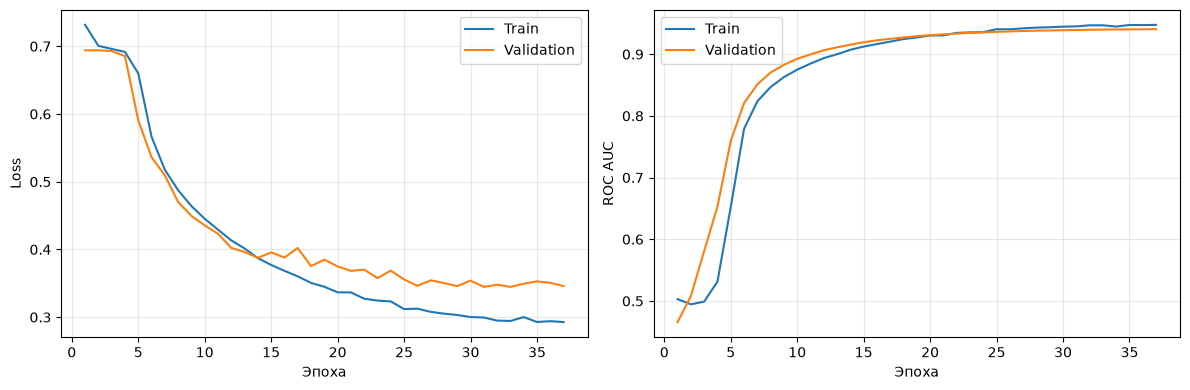

Лучшая эпоха по validation loss: 33


In [25]:
history = []
best_loss = float('inf')
stale_epochs = 0
for epoch in range(1, EPOCHS + 1):
    train_metrics, _, _ = run_epoch(train_loader, training=True)
    val_metrics, _, _ = run_epoch(val_loader)
    history.append({'epoch': epoch,
                    **{f'train_{key}': value for key, value in train_metrics.items()},
                    **{f'val_{key}': value for key, value in val_metrics.items()},
                    'lr': optimizer.param_groups[0]['lr']})
    print(f"Эпоха {epoch}: train loss={train_metrics['loss']:.4f}, "
          f"val loss={val_metrics['loss']:.4f}, val AUC={val_metrics['roc_auc']:.4f}")
    if val_metrics['loss'] < best_loss:
        best_loss = val_metrics['loss']
        stale_epochs = 0
        torch.save({'state_dict': model.state_dict(), 'config': model_config,
                    'epoch': epoch, 'val_loss': best_loss}, ARTIFACTS / 'best_model.pt')
    else:
        stale_epochs += 1
    pd.DataFrame(history).to_csv(ARTIFACTS / 'history.csv', index=False)
    if stale_epochs >= PATIENCE:
        break

history = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric, title in zip(axes, ['loss', 'roc_auc'], ['Loss', 'ROC AUC']):
    ax.plot(history.epoch, history[f'train_{metric}'], label='Train')
    ax.plot(history.epoch, history[f'val_{metric}'], label='Validation')
    ax.set(xlabel='Эпоха', ylabel=title)
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

checkpoint = torch.load(ARTIFACTS / 'best_model.pt', map_location='cpu', weights_only=True)
model.load_state_dict(checkpoint['state_dict'])
model.eval()
print('Лучшая эпоха по validation loss:', checkpoint['epoch'])

# Evaluation

Evaluate the model you trained on the test dataset. Plot the ROC curve.

,Test
loss,0.3654
accuracy,0.8558
roc_auc,0.9334
f1,0.8519


              precision    recall  f1-score   support

    negative     0.8383    0.8816    0.8594     12500
    positive     0.8751    0.8299    0.8519     12500

    accuracy                         0.8558     25000
   macro avg     0.8567    0.8558    0.8557     25000
weighted avg     0.8567    0.8558    0.8557     25000



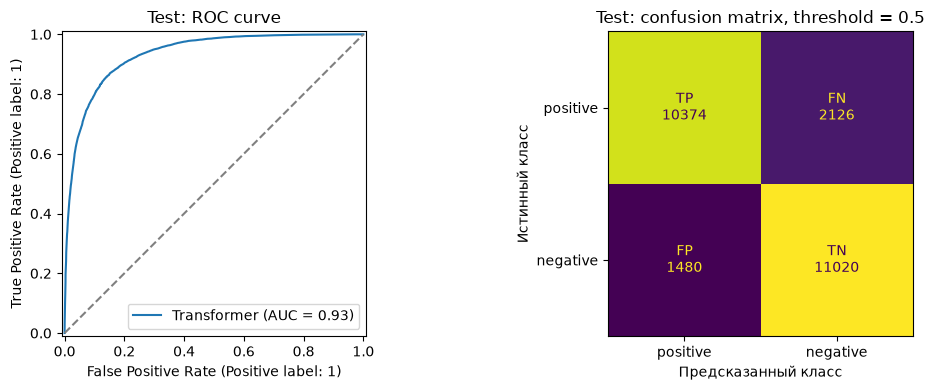

In [26]:
test_metrics, test_labels, test_probs = run_epoch(test_loader)
test_predictions = (test_probs >= 0.5).astype(int)
test_metrics['f1'] = f1_score(test_labels, test_predictions)
display(pd.Series(test_metrics, name='Test').to_frame().round(4))
print(classification_report(test_labels, test_predictions,
                            target_names=['negative', 'positive'], digits=4))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
RocCurveDisplay.from_predictions(test_labels, test_probs, ax=axes[0], name='Transformer')
axes[0].plot([0, 1], [0, 1], '--', color='gray')
axes[0].set_title('Test: ROC curve')
matrix = ConfusionMatrixDisplay.from_predictions(
    test_labels, test_predictions, labels=[1, 0],
    display_labels=['positive', 'negative'], values_format='d',
    ax=axes[1], colorbar=False,
)
for row, names in enumerate([['TP', 'FN'], ['FP', 'TN']]):
    for col, name in enumerate(names):
        matrix.text_[row, col].set_text(f'{name}\n{matrix.confusion_matrix[row, col]:d}')
axes[1].set_xlabel('Предсказанный класс')
axes[1].set_ylabel('Истинный класс')
axes[1].set_title('Test: confusion matrix, threshold = 0.5')
plt.tight_layout()
plt.show()
pd.Series(test_metrics).to_json(ARTIFACTS / 'test_metrics.json', indent=2)
pd.DataFrame({'label': test_labels, 'probability_positive': test_probs,
              'prediction': test_predictions}).to_csv(ARTIFACTS / 'test_predictions.csv', index=False)

Inspect the best model performance closer. Come up with some sentences (in English). Does the model output sensible results?

In [27]:
@torch.no_grad()
def probability_text(text, model, max_length=None):
    model.eval()
    max_length = min(max_length or model.max_length, model.max_length)
    ids = torch.tensor([tokenizer.encode(text, max_length)], device=next(model.parameters()).device)
    return model(ids).sigmoid().item()


def label_text(text, model, threshold=0.5, max_length=None):
    return int(probability_text(text, model, max_length) >= threshold)

In [28]:
examples = [
    'I loved this movie. The acting was excellent and the story was moving.',
    'This was a boring, poorly written movie. I regret watching it.',
    'The movie was not good.',
    'The movie was not bad at all.',
    'The actors were great, but the story was dull and disappointing.',
    'The beginning was slow, but the ending made the whole movie worth watching.',
]
example_probs = [probability_text(text, model) for text in examples]
display(pd.DataFrame({
    'Text': examples,
    'P(positive)': example_probs,
    'Prediction': ['positive' if p >= 0.5 else 'negative' for p in example_probs],
}))


,Text,P(positive),Prediction
0,I loved this movie. The acting was excellent a...,0.989066,positive
1,"This was a boring, poorly written movie. I reg...",0.006699,negative
2,The movie was not good.,0.976883,positive
3,The movie was not bad at all.,0.006988,negative
4,"The actors were great, but the story was dull ...",0.054996,negative
5,"The beginning was slow, but the ending made th...",0.100118,negative


# Bonus

Inspect the model attention scores with respect to words and punctuation in the sentence. What does the model consider when classifying the sentence.

In [29]:
@torch.no_grad()
def inspect_attention(text, model):
    model.eval()
    tokens = ['[CLS]'] + tokenizer.tokenize(text)[:model.max_length - 1]
    ids = torch.tensor([tokenizer.encode(text, model.max_length)], device=next(model.parameters()).device)
    logits, attention = model(ids, return_attention=True)
    last_attention = attention[-1][0].float().cpu().numpy()
    cls_attention = last_attention[:, 0, :]
    fig, axes = plt.subplots(2, 1, figsize=(max(10, len(tokens) * 0.5), 8))
    plot = axes[0].imshow(cls_attention, aspect='auto', cmap='Blues')
    axes[0].set_xticks(range(len(tokens)), tokens, rotation=60, ha='right')
    axes[0].set_yticks(range(len(cls_attention)), [f'Head {i + 1}' for i in range(len(cls_attention))])
    axes[0].set_title('Attention от [CLS] к токенам: последний блок')
    fig.colorbar(plot, ax=axes[0])
    plot = axes[1].imshow(last_attention.mean(axis=0), cmap='Blues')
    axes[1].set_xticks(range(len(tokens)), tokens, rotation=60, ha='right')
    axes[1].set_yticks(range(len(tokens)), tokens)
    axes[1].set(xlabel='К каким токенам обращаемся (key)', ylabel='Какой токен обращается (query)',
                title='Среднее attention по головам последнего блока')
    fig.colorbar(plot, ax=axes[1])
    plt.tight_layout()
    plt.show()
    print('P(positive):', round(logits.sigmoid().item(), 4))
    weights = cls_attention.mean(axis=0)
    return pd.DataFrame({'Position': range(len(tokens)), 'Token': tokens,
                         'Attention from CLS': weights}).sort_values('Attention from CLS', ascending=False)

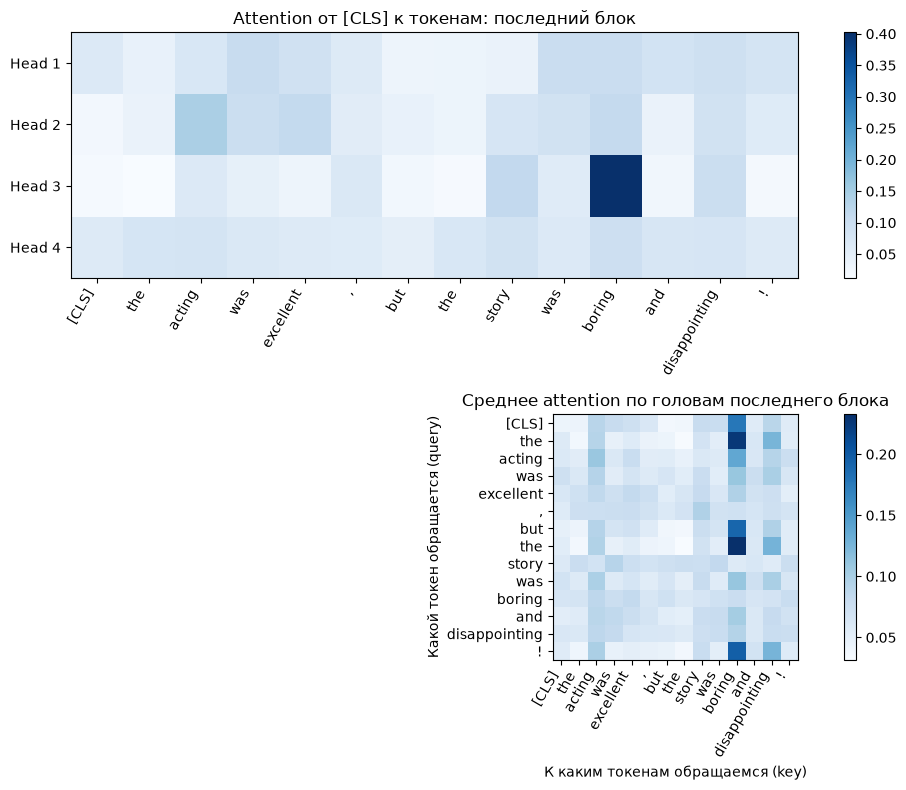

P(positive): 0.0173


,Position,Token,Attention from CLS
10,10,boring,0.177306
2,2,acting,0.090268
12,12,disappointing,0.088943
3,3,was,0.079871
8,8,story,0.078916
9,9,was,0.078196
4,4,excellent,0.073727
5,5,",",0.062126
13,13,!,0.055509
11,11,and,0.055377


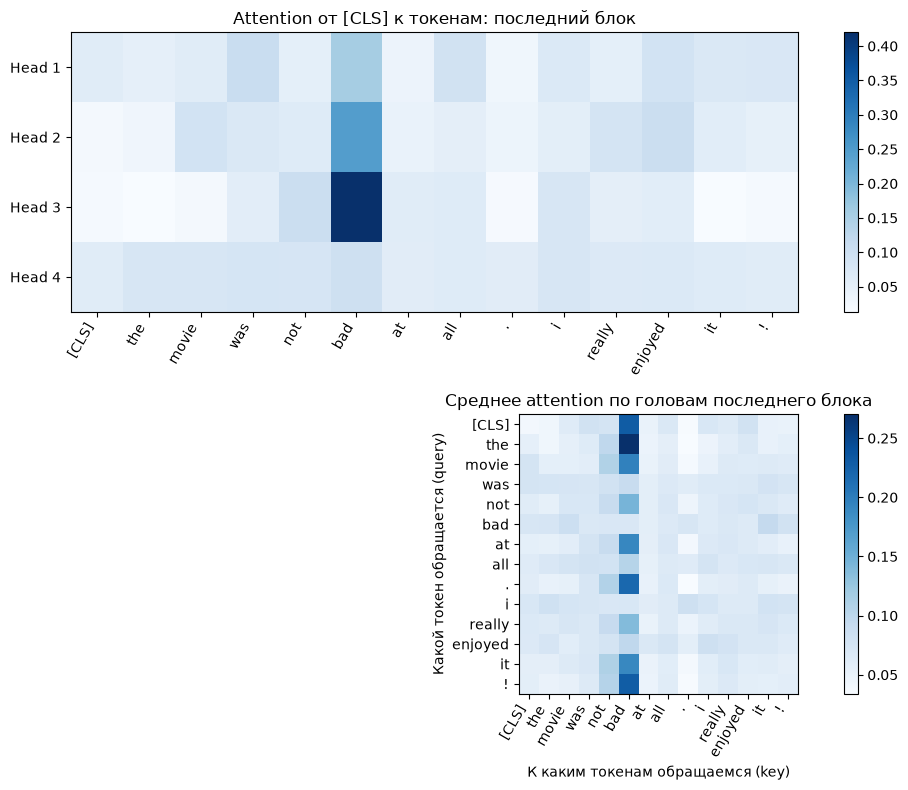

P(positive): 0.0147


In [30]:
attention_text = 'The acting was excellent, but the story was boring and disappointing!'
attention_table = inspect_attention(attention_text, model)
display(attention_table.head(12))
inspect_attention('The movie was not bad at all. I really enjoyed it!', model);


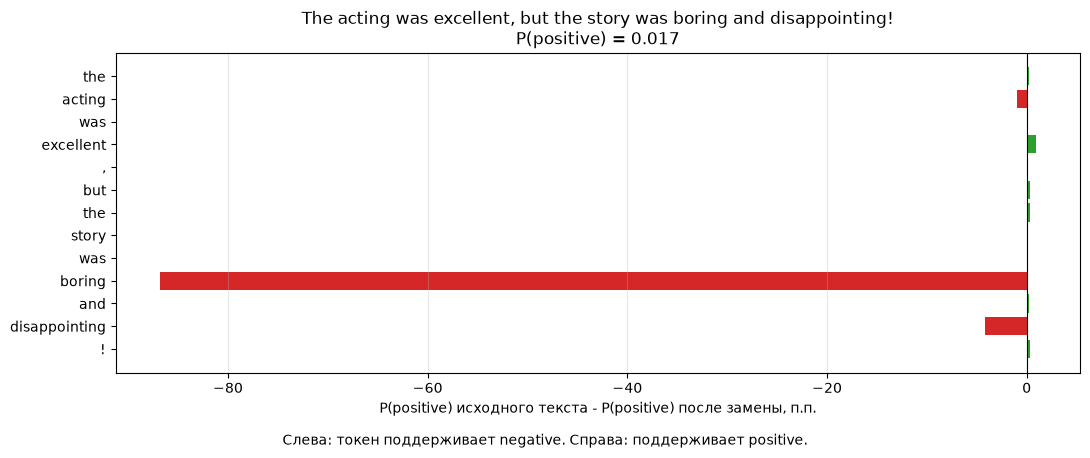

,Token,Position,P(positive) before,P(positive) with UNK,"Effect, pp"
0,the,1,0.0173,0.0151,0.2267
1,acting,2,0.0173,0.0266,-0.9221
2,was,3,0.0173,0.0159,0.1478
3,excellent,4,0.0173,0.0079,0.9484
4,",",5,0.0173,0.0170,0.0327
5,but,6,0.0173,0.0144,0.2977
6,the,7,0.0173,0.0137,0.3597
7,story,8,0.0173,0.0167,0.0627
8,was,9,0.0173,0.0165,0.0852
9,boring,10,0.0173,0.8858,-86.8506


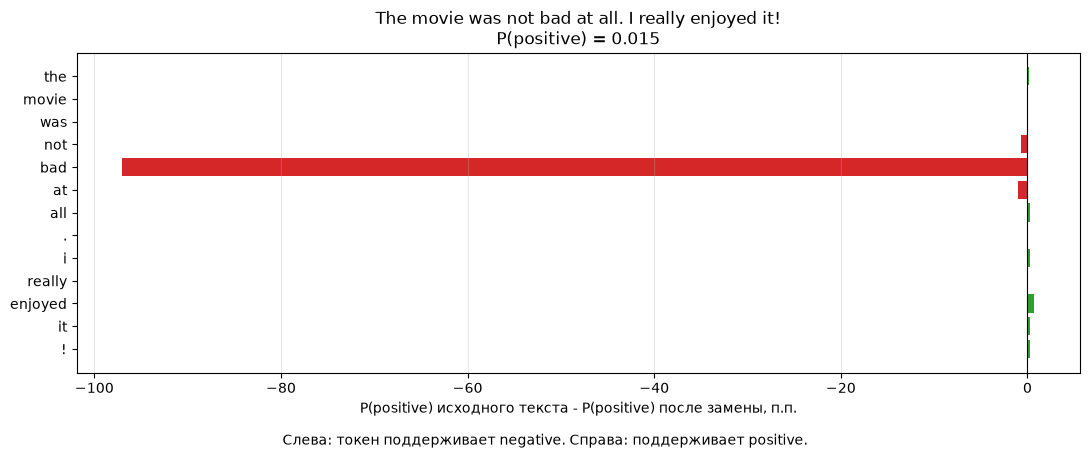

In [31]:
@torch.no_grad()
def replace_tokens(text, model, positions=None):
    model.eval()
    ids = torch.tensor([tokenizer.encode(text, model.max_length)], device=next(model.parameters()).device)
    tokens = ['[CLS]'] + tokenizer.tokenize(text)[:model.max_length - 1]
    original_probability = model(ids).sigmoid().item()
    if positions is None:
        positions = range(1, len(tokens))
    rows = []
    for position in positions:
        changed = ids.clone()
        changed[0, position] = tokenizer.unk_token_id
        probability = model(changed).sigmoid().item()
        rows.append({'Token': tokens[position], 'Position': position,
                     'P(positive) before': original_probability,
                     'P(positive) with UNK': probability,
                     'Effect, pp': 100 * (original_probability - probability)})
    return pd.DataFrame(rows)


def plot_token_effects(text, model):
    effects = replace_tokens(text, model)
    colors = ['tab:green' if value >= 0 else 'tab:red' for value in effects['Effect, pp']]
    fig, ax = plt.subplots(figsize=(11, max(4, len(effects) * 0.35)))
    ax.barh(range(len(effects)), effects['Effect, pp'], color=colors)
    ax.set_yticks(range(len(effects)), effects.Token)
    ax.invert_yaxis()
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_xlabel('P(positive) исходного текста - P(positive) после замены, п.п.')
    ax.set_title(f"{text}\nP(positive) = {effects['P(positive) before'].iloc[0]:.3f}")
    ax.grid(axis='x', alpha=0.3)
    fig.text(0.5, 0.01, 'Слева: токен поддерживает negative. Справа: поддерживает positive.',
             ha='center')
    plt.tight_layout(rect=(0, 0.04, 1, 1))
    plt.show()
    return effects


effects = plot_token_effects(attention_text, model)
display(effects.round(4))
plot_token_effects('The movie was not bad at all. I really enjoyed it!', model);


In [32]:
negation_pairs = [
    ('The movie was good.', 'The movie was not good.', -1),
    ('The movie was bad.', 'The movie was not bad.', 1),
    ('I enjoyed this movie.', 'I did not enjoy this movie.', -1),
    ('I like this movie.', 'I do not like this movie.', -1),
    ('I recommend this movie.', 'I do not recommend this movie.', -1),
    ('The movie was boring.', 'The movie was not boring.', 1),
    ('The movie was worth watching.', 'The movie was not worth watching.', -1),
    ('The acting was excellent.', 'The acting was not excellent.', -1),
    ('The story was interesting.', 'The story was not interesting.', -1),
    ('The film was entertaining.', 'The film was not entertaining.', -1),
    ('I thought the acting was good and the story was interesting.',
     'I thought the acting was not good and the story was not interesting.', -1),
    ('After watching the entire movie, I can say that it was worth my time.',
     'After watching the entire movie, I can say that it was not worth my time.', -1),
]
negation_rows = []
for original, negated, direction in negation_pairs:
    before = probability_text(original, model)
    after = probability_text(negated, model)
    unknown = sum(tokenizer.encode(text, model.max_length).count(tokenizer.unk_token_id)
                  for text in [original, negated])
    negation_rows.append({
        'Original': original, 'With negation': negated,
        'P(positive) original': before, 'P(positive) negated': after,
        'Change, pp': 100 * (after - before),
        'Expected': 'increase' if direction > 0 else 'decrease',
        'Direction correct': (after - before) * direction > 0,
        'Prediction changed': (before >= 0.5) != (after >= 0.5),
        'UNK': unknown,
    })
negation_results = pd.DataFrame(negation_rows)
with pd.option_context('display.max_colwidth', None):
    display(negation_results.round(4))
print('Пар с ожидаемым изменением:', int(negation_results['Direction correct'].sum()), '/', len(negation_results))
print('Пар со сменой класса:', int(negation_results['Prediction changed'].sum()), '/', len(negation_results))

,Original,With negation,P(positive) original,P(positive) negated,"Change, pp",Expected,Direction correct,Prediction changed,UNK
0,The movie was good.,The movie was not good.,0.9902,0.9769,-1.3277,decrease,True,False,0
1,The movie was bad.,The movie was not bad.,0.0075,0.0070,-0.0458,increase,False,False,0
2,I enjoyed this movie.,I did not enjoy this movie.,0.9935,0.9897,-0.3834,decrease,True,False,0
3,I like this movie.,I do not like this movie.,0.9808,0.1769,-80.3864,decrease,True,True,0
4,I recommend this movie.,I do not recommend this movie.,0.9923,0.9779,-1.4450,decrease,True,False,0
5,The movie was boring.,The movie was not boring.,0.0087,0.0077,-0.0991,increase,False,False,0
6,The movie was worth watching.,The movie was not worth watching.,0.9902,0.9773,-1.2864,decrease,True,False,0
7,The acting was excellent.,The acting was not excellent.,0.9931,0.9927,-0.0466,decrease,True,False,0
8,The story was interesting.,The story was not interesting.,0.9900,0.8535,-13.6510,decrease,True,False,0
9,The film was entertaining.,The film was not entertaining.,0.9909,0.9807,-1.0224,decrease,True,False,0


Пар с ожидаемым изменением: 10 / 12
Пар со сменой класса: 3 / 12
